# 4. Exploratory Data Analysis — Visualization
The following code uses the course's prepared dataset. It creates the main plots discussed in the IBM capstone report.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

df = pd.read_csv("https://raw.githubusercontent.com/chuksoo/IBM-Data-Science-Capstone-SpaceX/main/dataset_part_2.csv")
print("Shape:", df.shape)
print(df.columns.tolist())
display(df.head())
sns.set_theme()

Shape: (90, 18)
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


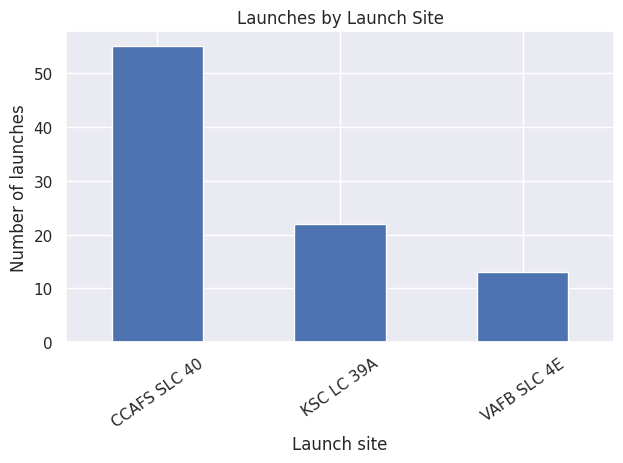

In [2]:
# Launch counts by site
site_col = "LaunchSite" if "LaunchSite" in df.columns else "Launch_Site"
if site_col in df.columns:
    df[site_col].value_counts().plot(kind="bar", title="Launches by Launch Site")
    plt.xlabel("Launch site"); plt.ylabel("Number of launches"); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

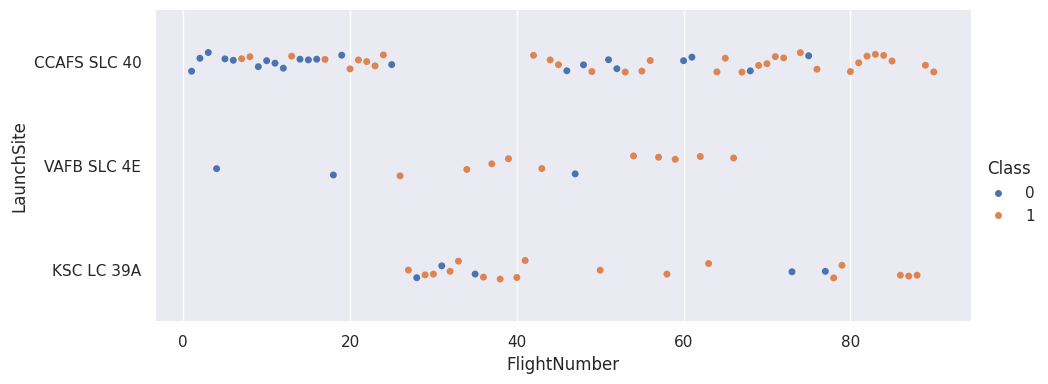

In [3]:
# Flight number versus launch site
if "FlightNumber" in df.columns and site_col in df.columns:
    sns.catplot(data=df, x="FlightNumber", y=site_col, hue="Class", aspect=2.5, height=4)
    plt.show()

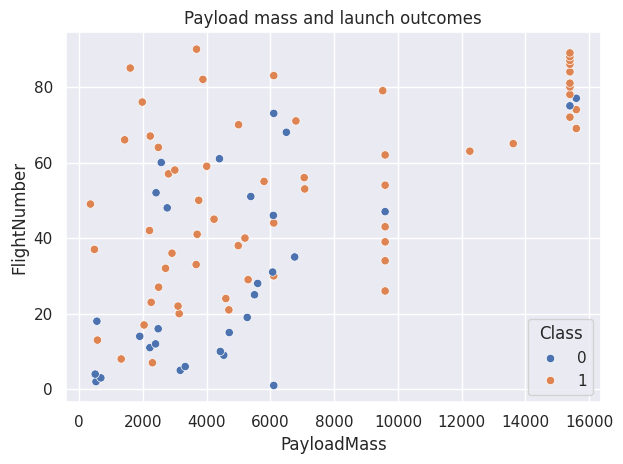

In [4]:
# Payload mass versus launch site
if "PayloadMass" in df.columns and site_col in df.columns:
    sns.scatterplot(data=df, x="PayloadMass", y="FlightNumber" if "FlightNumber" in df.columns else site_col,
                    hue="Class" if "Class" in df.columns else None)
    plt.title("Payload mass and launch outcomes")
    plt.tight_layout(); plt.show()

,SuccessRate
Orbit,
ES-L1,1.000000
GEO,1.000000
HEO,1.000000
SSO,1.000000
VLEO,0.857143
LEO,0.714286
PO,0.666667
MEO,0.666667
ISS,0.619048


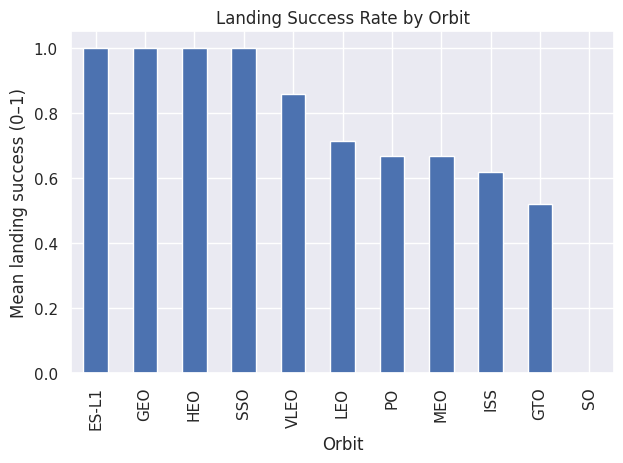

In [5]:
# Success rate by orbit
if "Orbit" in df.columns and "Class" in df.columns:
    orbit_rate = df.groupby("Orbit", dropna=False)["Class"].mean().sort_values(ascending=False)
    display(orbit_rate.rename("SuccessRate").to_frame())
    orbit_rate.plot(kind="bar", title="Landing Success Rate by Orbit")
    plt.ylabel("Mean landing success (0–1)"); plt.tight_layout(); plt.show()

,SuccessRate
Year,
2010,0.000000
2012,0.000000
2013,0.000000
2014,0.333333
2015,0.333333
2016,0.625000
2017,0.833333
2018,0.611111
2019,0.900000


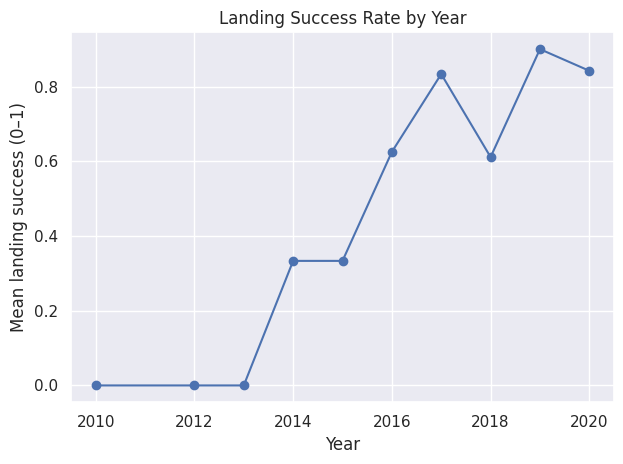

In [6]:
# Success trend by year if a date column is available
date_col = next((c for c in ["Date", "date", "DateUTC", "date_utc"] if c in df.columns), None)
if date_col and "Class" in df.columns:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df["Year"] = df[date_col].dt.year
    yearly = df.groupby("Year")["Class"].mean()
    display(yearly.to_frame("SuccessRate"))
    yearly.plot(marker="o", title="Landing Success Rate by Year")
    plt.ylabel("Mean landing success (0–1)"); plt.tight_layout(); plt.show()
else:
    print("No recognized date column; skip yearly trend or adapt date_col to the actual column name.")